# 01 · Hạn chế của mô hình cơ sở và thiết kế đặc trưng

Nhóm 13 · Bài kiểm tra 3 · Tiêu chí 1–3

Logistic Regression của KT2 là đối chứng. Notebook dùng Validation để xem
lỗi, và dùng các fold của Train để đo tác động của đặc trưng.
Chạy `code/run_experiments_kt3.py` nếu chưa có JSON và biểu đồ.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, display

for directory in (Path.cwd(), Path.cwd() / "code"):
    if (directory / "workflow_kt3.py").is_file():
        sys.path.insert(0, str(directory))
        break

from workflow_kt3 import ROOT, SUMMARY_PATH, load_splits

train, validation, test = load_splits()
with SUMMARY_PATH.open(encoding="utf-8") as summary_file:
    summary = json.load(summary_file)

In [2]:
from workflow_kt3 import NEW_COLUMNS, engineer_features, make_candidates

pd.DataFrame(
    [(name, len(part.y), part.y.mean()) for name, part in
     [("Train", train), ("Validation", validation), ("Test", test)]],
    columns=["Tập", "Số hồ sơ", "Tỷ lệ nhãn duyệt"],
)

,Tập,Số hồ sơ,Tỷ lệ nhãn duyệt
0,Train,35000,0.550457
1,Validation,7500,0.550533
2,Test,7500,0.550400


## Phân tích lỗi và giới hạn mô hình tuyến tính

FP là dự đoán duyệt trên hồ sơ có nhãn từ chối. FN là dự đoán từ chối
trên hồ sơ có nhãn duyệt. So sánh trung vị của các nhóm lỗi với Validation
để tìm khác biệt về điểm tín dụng và thu nhập. Đường cong học tập cho
biết hiệu quả của tăng kích thước huấn luyện với cấu hình hiện tại.

,Nhóm,Số hồ sơ,credit_score,debt_to_income_ratio,annual_income
0,FP,503,653.0,0.190,41110.0
1,FN,470,625.5,0.314,39922.5
2,Toàn bộ Validation,7500,644.0,0.265,41415.0


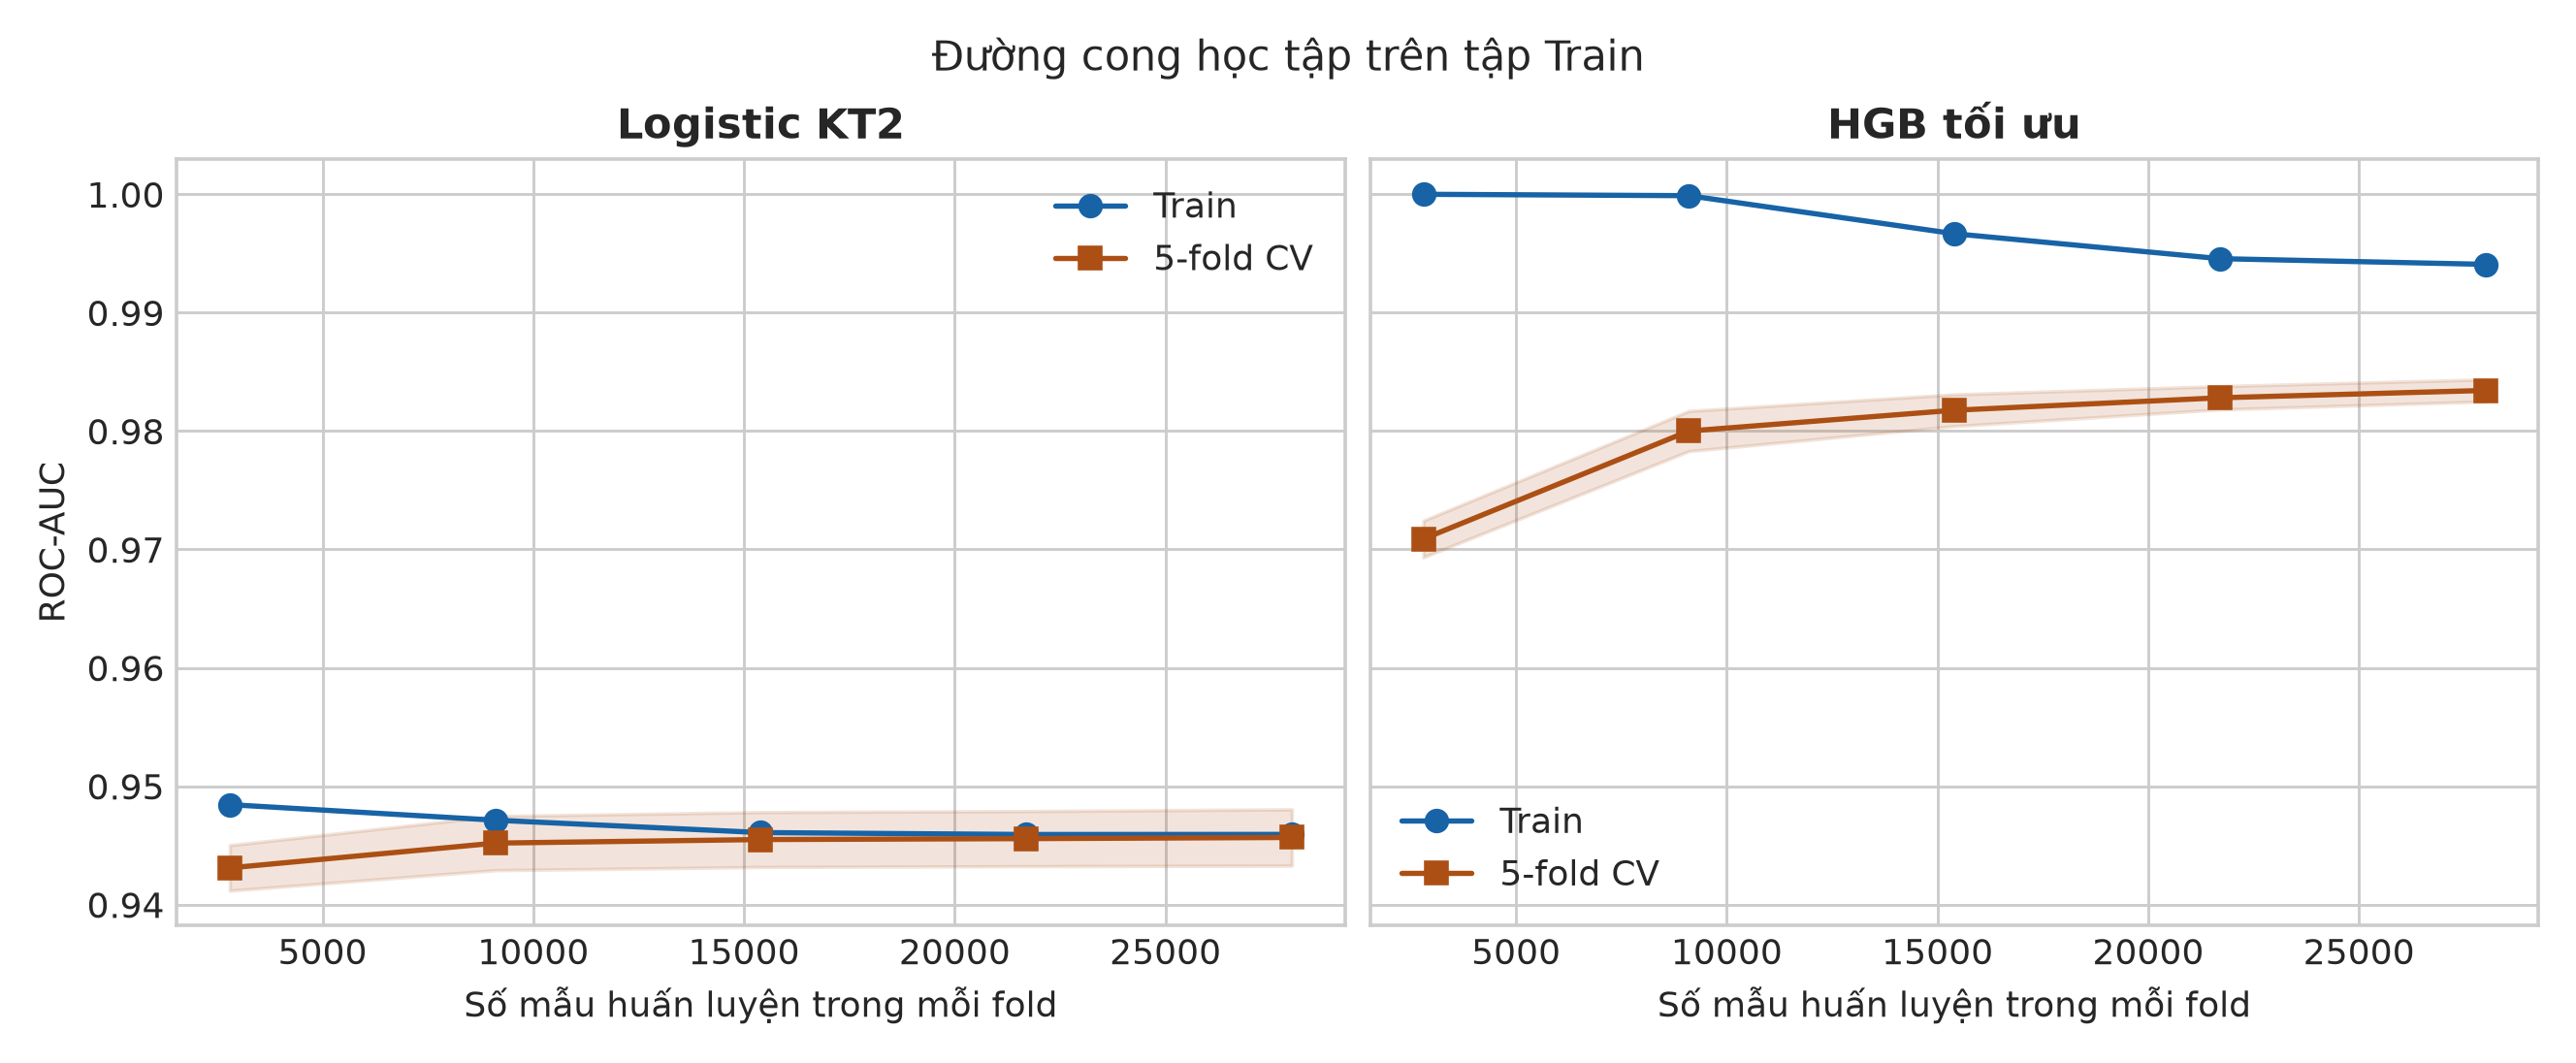

In [3]:
display(pd.DataFrame(summary["baseline_val_error_profile"]).round(4))
display(Image(filename=str(ROOT / "images" / "duong_cong_hoc_tap_kt3.png"), width=900))

## Giải pháp và tác động đo được

| Hạn chế | Giải pháp |
|---|---|
| Hệ số tuyến tính chưa mô tả linh hoạt tương tác giữa các thuộc tính | So sánh với CART, Random Forest và HistGradientBoosting |
| Nhiều thuộc tính có ý nghĩa khi biểu diễn theo tỷ số hoặc kết hợp | Tạo 5 đặc trưng từ các cột đầu vào và đo tác động bằng các cặp đối chứng |
| Cấu hình cây ảnh hưởng đến độ phức tạp và chất lượng trên fold kiểm định | Tìm siêu tham số trên Train bằng GridSearchCV |

Năm đặc trưng lần lượt là tỷ lệ dư nợ cộng khoản vay trên thu nhập, tỷ
lệ tiết kiệm trên khoản vay, chỉ số lịch sử tín dụng tổng hợp, tích DTI
với lãi suất và tỷ lệ thâm niên trên tuổi trưởng thành. Các phép tính
chỉ sử dụng thông tin trong từng hồ sơ.

In [4]:
display(engineer_features(train.X).loc[:, list(NEW_COLUMNS)].head().round(4))

rows = pd.DataFrame(summary["ablation_study"])
display(rows.iloc[:2][["So sánh", "AUC trước", "AUC sau", "Δ ROC-AUC",
                        "Δ Accuracy (điểm %)", "Δ F1-Macro"]].round(5))

,debt_service_ratio,savings_to_loan_ratio,credit_risk_score,dti_interest_burden,employment_stability
21145,0.6069,0.0148,0.0,1.5912,0.2200
42122,0.3306,0.0077,0.0,2.9155,0.0000
15264,0.7182,0.1029,1.5,1.5366,0.6800
12561,0.5051,0.6252,8.5,3.4838,0.8429
42372,0.4719,0.4044,0.0,2.0551,0.4571


,So sánh,AUC trước,AUC sau,Δ ROC-AUC,Δ Accuracy (điểm %),Δ F1-Macro
0,Thêm đặc trưng cho Logistic,0.94567,0.94661,0.00094,0.19429,0.00196
1,Thêm đặc trưng cho HGB,0.98360,0.98337,-0.00023,0.01714,0.00020


Hai hàng sử dụng cùng mô hình, cùng fold và chỉ thay đổi tập đặc trưng.
Vì vậy có thể đo tác động thêm đặc trưng cho từng họ mô hình. Dấu và
độ lớn của thay đổi phụ thuộc thuật toán và chỉ số đang xét.